# 08 — Explicabilité des modèles (SHAP)

**Objectifs**
1. Comprendre **sur quoi** reposent les décisions des deux modèles retenus (`LightGBM complet` et `LightGBM transaction`) ;
2. **Vérifier** que le modèle `complet` s'appuie bien sur les artefacts du simulateur identifiés en EDA (compte vidé, soldes destinataires nuls, erreurs de solde) ;
3. **Relier** les explications aux hypothèses H1 à H5 du cadrage ;
4. Expliquer des décisions **individuelles** : une fraude détectée, une fraude manquée, une fausse alerte.

**Méthode : SHAP** (Lundberg & Lee, 2017). Chaque prédiction est décomposée en une somme de contributions, une par variable :

$$\text{score}(x) = \text{valeur de base} + \sum_{j} \text{SHAP}_j(x)$$

Le score est exprimé en **log-odds** (probabilité = 1 / (1 + e^{-score})). Une contribution **positive** pousse vers « fraude », une contribution **négative** vers « légitime ». `TreeExplainer` calcule ces valeurs **exactement** pour les modèles à base d'arbres.

Pourquoi pas les coefficients de la régression logistique ? Le notebook 05 a montré qu'ils deviennent trompeurs quand les variables sont corrélées (`orig_solde_nul` à +6,2). SHAP répartit l'effet de façon cohérente et capte les effets non linéaires.

**Données** : la **validation** (le test a été utilisé une seule fois, au notebook 07).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import shap

from src.config import TARGET, MODELS_DIR, RESULTS_DIR, RANDOM_STATE
from src.split import load_split
from src.features import TRANSACTION_FEATURES, BALANCE_FEATURES
from src.explain import compute_shap, mean_abs_shap, group_share, plot_contributions
from src.evaluate import MODEL_COLORS, save_results
from src.viz import set_style, save_fig, COLOR_LEGIT, COLOR_FRAUD, TEXT_SECONDARY

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

val = load_split("val")
models = {fs: joblib.load(MODELS_DIR / f"lightgbm_{fs}.joblib") for fs in ["complet", "transaction"]}
seuils = pd.read_csv(RESULTS_DIR / "07_seuils_validation.csv", index_col="modele")["seuil_optimal"]
THRESHOLD = {fs: seuils[f"LightGBM ({fs})"] for fs in models}
print("Seuils retenus (notebook 07) :", {k: round(v, 4) for k, v in THRESHOLD.items()})

Seuils retenus (notebook 07) : {'complet': np.float64(0.9999), 'transaction': np.float64(0.8431)}


### Échantillon d'explication

Calculer SHAP sur les 346 000 transactions de la validation est inutile : on prend **toutes les fraudes** (498) et un **échantillon aléatoire de 20 000 transactions légitimes**. Cet échantillon est **stratifié** : pour l'importance globale, chaque légitime reçoit un poids égal à (nombre de légitimes) / 20 000, afin de retrouver les proportions réelles.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
fraud_idx = val.index[val[TARGET] == 1]
legit_all = val.index[val[TARGET] == 0]
legit_idx = rng.choice(legit_all, size=20_000, replace=False)
sample = val.loc[np.r_[fraud_idx, legit_idx]]
y_s = sample[TARGET].to_numpy()
weights = np.where(y_s == 1, 1.0, len(legit_all) / len(legit_idx))

shap_vals, feats, base = {}, {}, {}
for fs, model in models.items():
    shap_vals[fs], feats[fs], base[fs] = compute_shap(model, sample)
    print(f"{fs:<12} : {shap_vals[fs].shape[1]:>2} variables, valeur de base = {base[fs]:.2f} log-odds")

complet      : 15 variables, valeur de base = -13.45 log-odds


transaction  :  5 variables, valeur de base = -1.31 log-odds


## 1. Importance globale des variables

L'importance d'une variable est la **moyenne des |SHAP|** : de combien, en moyenne, elle déplace le score (pondérée pour refléter la population réelle).

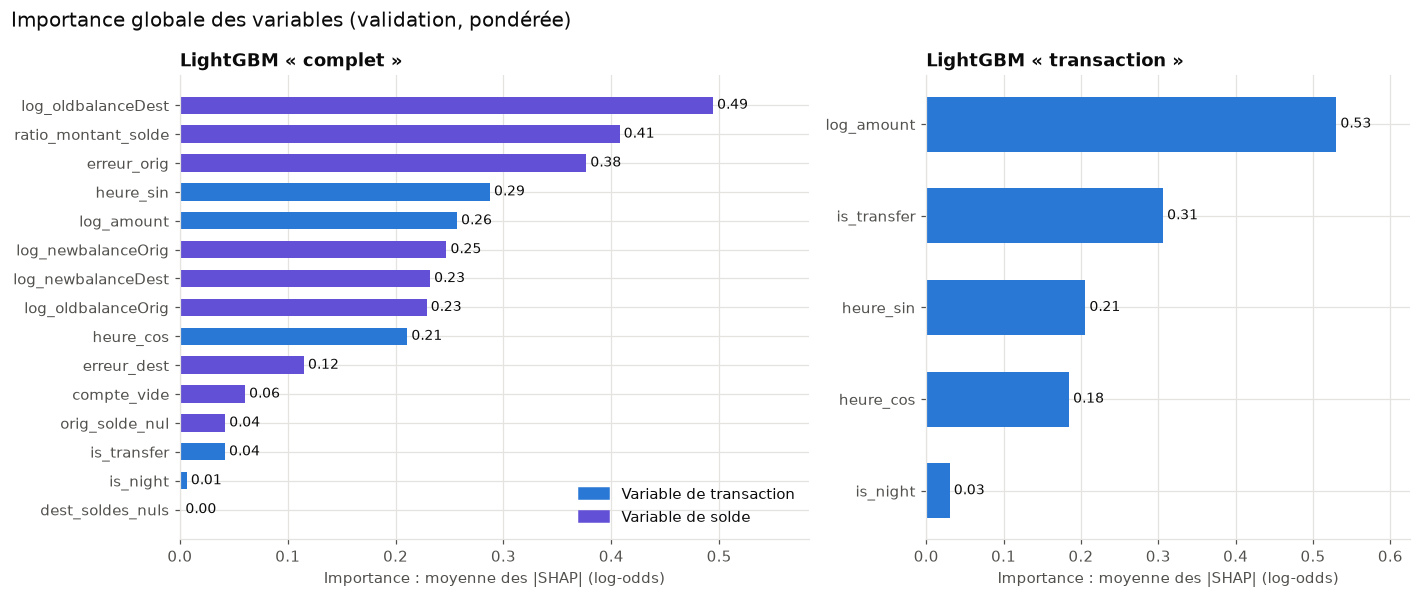

Modèle complet : 73.3% de l'importance totale portée par les variables de solde


In [3]:
importance = {fs: mean_abs_shap(shap_vals[fs], weights) for fs in models}
_ = save_results(pd.concat(importance, axis=1).rename_axis("variable"), "08_importance_shap")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
for ax, fs in zip(axes, ["complet", "transaction"]):
    imp = importance[fs].iloc[::-1]
    is_balance = [f in BALANCE_FEATURES for f in imp.index]
    ax.barh(imp.index, imp.to_numpy(), height=0.6,
            color=[MODEL_COLORS[2] if b else MODEL_COLORS[0] for b in is_balance])
    for y, v in enumerate(imp.to_numpy()):
        ax.text(v, y, f" {v:.2f}", va="center", fontsize=9)
    ax.set_xlabel("Importance : moyenne des |SHAP| (log-odds)")
    ax.set_title(f"LightGBM « {fs} »", loc="left")
    ax.set_xlim(0, imp.max() * 1.18)
handles = [plt.Rectangle((0, 0), 1, 1, color=MODEL_COLORS[0]), plt.Rectangle((0, 0), 1, 1, color=MODEL_COLORS[2])]
axes[0].legend(handles, ["Variable de transaction", "Variable de solde"], loc="lower right")
fig.suptitle("Importance globale des variables (validation, pondérée)", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save_fig(fig, "08_importance_shap")
plt.show()

share = group_share(shap_vals["complet"], {"transaction": TRANSACTION_FEATURES, "soldes": BALANCE_FEATURES}, weights)
print(f"Modèle complet : {share['soldes']:.1%} de l'importance totale portée par les variables de solde")

L'importance pondérée reflète la population réelle, composée à 99,9 % de transactions légitimes : elle mesure surtout comment le modèle **ordonne les légitimes entre elles**. Pour comprendre comment il **reconnaît une fraude**, on calcule aussi l'importance sur les seules fraudes.

In [4]:
fraud_importance = pd.concat({fs: shap_vals[fs][y_s == 1].abs().mean().sort_values(ascending=False)
                              for fs in models}, axis=1)
fraud_importance.sort_values("complet", ascending=False)

,complet,transaction
compte_vide,17.875,NaN
erreur_orig,3.313,NaN
log_newbalanceOrig,1.906,NaN
ratio_montant_solde,1.113,NaN
log_oldbalanceDest,0.965,NaN
log_amount,0.553,1.275
erreur_dest,0.537,NaN
log_newbalanceDest,0.425,NaN
heure_cos,0.238,0.390
log_oldbalanceOrig,0.224,NaN


**Lecture**
- **Modèle `complet`** : les variables de solde portent **73 %** de l'importance totale. Sur la population, `log_oldbalanceDest`, `ratio_montant_solde` et `erreur_orig` dominent. Sur les **fraudes**, une seule variable écrase toutes les autres : **`compte_vide`**, avec une contribution moyenne de **+17,9 log-odds** (le score passe d'une probabilité quasi nulle à une quasi-certitude). Viennent ensuite `erreur_orig` (3,3) et `log_newbalanceOrig` (1,9), qui décrivent le même phénomène : un compte émetteur vidé avec des soldes parfaitement cohérents.
- `compte_vide` a pourtant une importance **pondérée** très faible (0,06) : elle vaut 0 pour presque toutes les transactions, où elle ne contribue pas. Les deux mesures sont complémentaires : l'importance sur la population dit « quelles variables le modèle utilise le plus souvent », l'importance sur les fraudes dit « comment il reconnaît une fraude ».
- `dest_soldes_nuls` a une importance quasi nulle alors que l'EDA la montrait très discriminante (97,5 % de fraudes parmi les TRANSFER concernés). Elle est **redondante** avec `log_oldbalanceDest = 0` et `log_newbalanceDest = 0`, que les arbres utilisent à sa place. SHAP attribue l'effet aux variables effectivement utilisées par le modèle : une importance faible ne signifie pas qu'une variable est inutile, seulement qu'une autre porte déjà l'information.
- **Modèle `transaction`** : sur la population, le **montant** domine (0,53), suivi du **type** (0,31). Sur les **fraudes**, les trois variables **horaires** cumulent 1,88 (`heure_sin` 0,94, `is_night` 0,55, `heure_cos` 0,39), devant le montant (1,28) : c'est **l'heure** qui permet surtout de reconnaître une fraude. La section 4 montre pourquoi.

## 2. Sens des effets : diagrammes en essaim

Chaque point est une transaction de l'échantillon. La position horizontale donne la contribution SHAP de la variable, la couleur sa **valeur** (clair = faible, foncé = élevée). On lit à la fois **l'importance** (étalement) et **le sens** de l'effet (les valeurs élevées poussent-elles vers la fraude ?).

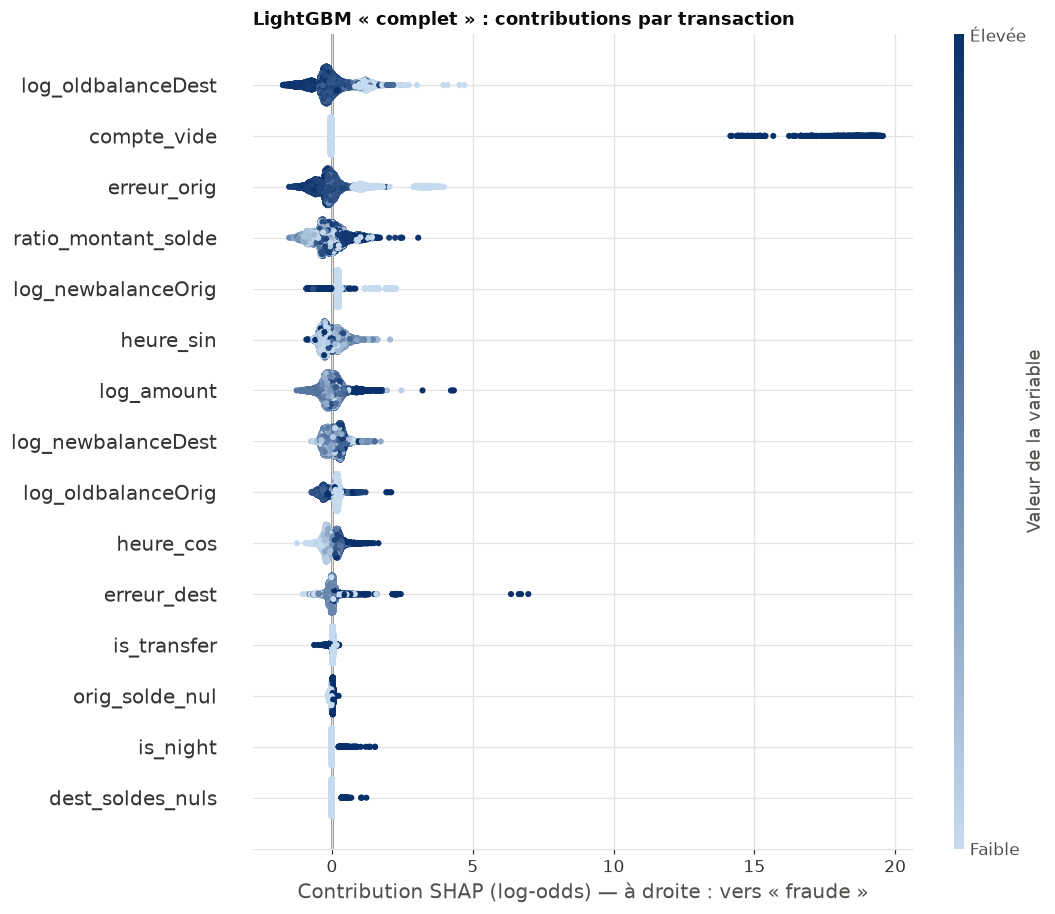

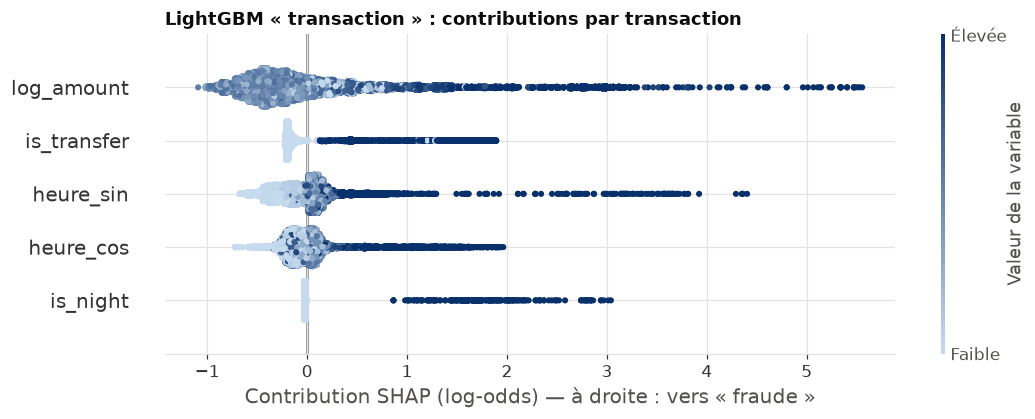

In [5]:
value_cmap = LinearSegmentedColormap.from_list("valeurs", ["#c6dbef", "#08306b"])
for fs in ["complet", "transaction"]:
    shap.summary_plot(shap_vals[fs].to_numpy(), feats[fs], cmap=value_cmap, show=False,
                      plot_size=(10, 0.45 * shap_vals[fs].shape[1] + 1.5), color_bar_label="Valeur de la variable")
    fig = plt.gcf()
    fig.axes[0].set_xlabel("Contribution SHAP (log-odds) — à droite : vers « fraude »")
    fig.axes[0].set_title(f"LightGBM « {fs} » : contributions par transaction", loc="left")
    fig.axes[-1].set_yticklabels(["Faible", "Élevée"])
    save_fig(fig, f"08_essaim_{fs}")
    plt.show()

**Lecture**
- **`compte_vide`** (modèle `complet`) : deux groupes nets. Les transactions où la variable vaut 1 reçoivent **+14 à +20 log-odds**, les autres exactement 0. C'est la traduction directe de l'artefact « compte vidé » (H3), qui concerne 97,6 % des fraudes et aucune transaction légitime.
- **`erreur_orig`** : les valeurs **faibles** (solde émetteur parfaitement cohérent) poussent vers la fraude, les écarts importants vers « légitime ». Dans PaySim, les soldes des fraudes sont exacts alors que ceux de nombreuses transactions légitimes sont incohérents (H4) : c'est encore un artefact.
- **`log_oldbalanceDest`** : un solde destinataire **nul** pousse vers la fraude, ce qui rejoint `dest_soldes_nuls`.
- **Modèle `transaction`** :
  - les montants **élevés** poussent fortement vers la fraude (jusqu'à +5,5) ;
  - `is_transfer = 1` pousse vers la fraude ;
  - `is_night = 1` ajoute de +1 à +3 ;
  - les valeurs élevées de `heure_cos` (proche de minuit) et de `heure_sin` (le matin) poussent elles aussi vers la fraude.

  Le sens de chaque effet est **cohérent avec les hypothèses H1, H2 et H5** de l'EDA.

## 3. Le modèle `complet` s'appuie-t-il sur les artefacts du simulateur ?

On mesure la contribution moyenne des variables binaires selon leur valeur, séparément pour les fraudes et les transactions légitimes.

In [6]:
rows = []
for f in ["compte_vide", "dest_soldes_nuls", "orig_solde_nul", "is_transfer", "is_night"]:
    for v in [0, 1]:
        m = feats["complet"][f].to_numpy() == v
        for cls, label in [(1, "fraudes"), (0, "légitimes")]:
            mm = m & (y_s == cls)
            rows.append({"variable": f, "valeur": v, "classe": label, "n": int(mm.sum()),
                         "shap_moyen": shap_vals["complet"][f].to_numpy()[mm].mean() if mm.any() else np.nan})
artefacts = pd.DataFrame(rows).pivot_table(index=["variable", "valeur"], columns="classe",
                                            values=["n", "shap_moyen"])
artefacts

n            shap_moyen          
classe                  fraudes  légitimes    fraudes légitimes
variable         valeur                                        
compte_vide      0        4.000 20,000.000     -0.025    -0.035
                 1      494.000      0.000     18.019       NaN
dest_soldes_nuls 0      249.000 19,996.000     -0.001    -0.001
                 1      249.000      4.000      0.431     0.623
is_night         0      346.000 19,894.000     -0.002    -0.004
                 1      152.000    106.000      0.433     0.482
is_transfer      0      249.000 16,127.000      0.053     0.028
                 1      249.000  3,873.000      0.063    -0.091
orig_solde_nul   0      498.000 10,462.000     -0.013    -0.045
                 1        0.000  9,538.000        NaN     0.038

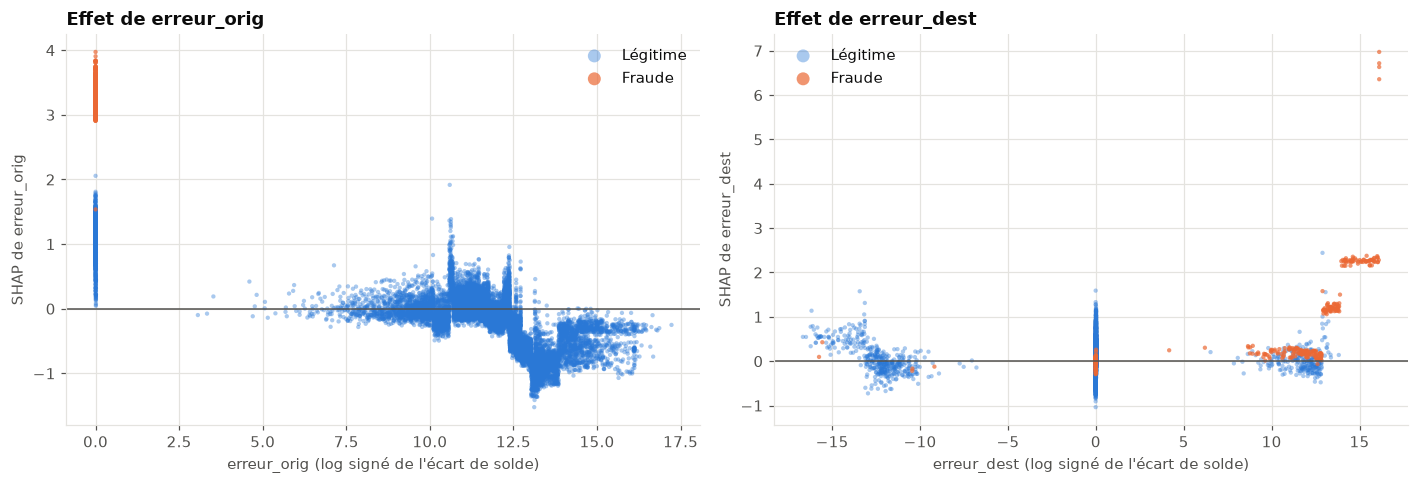

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, f in zip(axes, ["erreur_orig", "erreur_dest"]):
    x, s = feats["complet"][f].to_numpy(), shap_vals["complet"][f].to_numpy()
    for cls, color, label in [(0, COLOR_LEGIT, "Légitime"), (1, COLOR_FRAUD, "Fraude")]:
        m = y_s == cls
        ax.scatter(x[m], s[m], s=8, alpha=0.4 if cls == 0 else 0.7, color=color, label=label,
                   edgecolor="none")
    ax.axhline(0, color=TEXT_SECONDARY, linewidth=1)
    ax.set_xlabel(f"{f} (log signé de l'écart de solde)")
    ax.set_ylabel(f"SHAP de {f}")
    ax.set_title(f"Effet de {f}", loc="left")
    ax.legend(loc="best", markerscale=3)
fig.tight_layout()
save_fig(fig, "08_dependance_erreurs_solde")
plt.show()

**Verdict : oui, le modèle `complet` repose sur les artefacts du simulateur.**
- **Compte vidé (H3)** : les 494 fraudes concernées reçoivent en moyenne **+18,0 log-odds** de cette seule variable. Aucune transaction légitime de l'échantillon n'a `compte_vide = 1`. Les 4 fraudes restantes (plafonnées à 10 M) obtiennent 0 de cette variable et sont détectées par d'autres (section 5).
- **Erreurs de solde (H4)** :
  - `erreur_orig = 0` (solde émetteur exact) donne **+3 à +4** aux fraudes, contre +0 à +2 aux légitimes : le modèle a appris que les fraudes ont des soldes « trop parfaits » ;
  - un `erreur_dest` très élevé (≈ 13 à 16 en log signé : le destinataire **n'a pas été crédité**) donne +1 à +7 et concerne presque uniquement des fraudes.
- **Soldes destinataires nuls** : `dest_soldes_nuls = 1` apporte en moyenne +0,4 à +0,6, son information étant déjà portée par `log_oldbalanceDest`.
- ➡️ Ces mécanismes sont des **propriétés du simulateur**, pas des comportements de fraudeurs. Sur des données réelles, un fraudeur ne vide pas forcément le compte en une seule fois, et les soldes ne sont pas incohérents pour les clients légitimes. Ce modèle ne serait donc **pas transposable** tel quel.

## 4. Le modèle `transaction` : heure, montant et type (H1, H2, H5)

Sans les soldes, le modèle n'a que trois informations : le **type**, le **montant** et **l'heure** (encodée par `heure_sin`, `heure_cos` et `is_night`). On additionne les contributions des trois variables horaires pour obtenir un **effet de l'heure** unique.

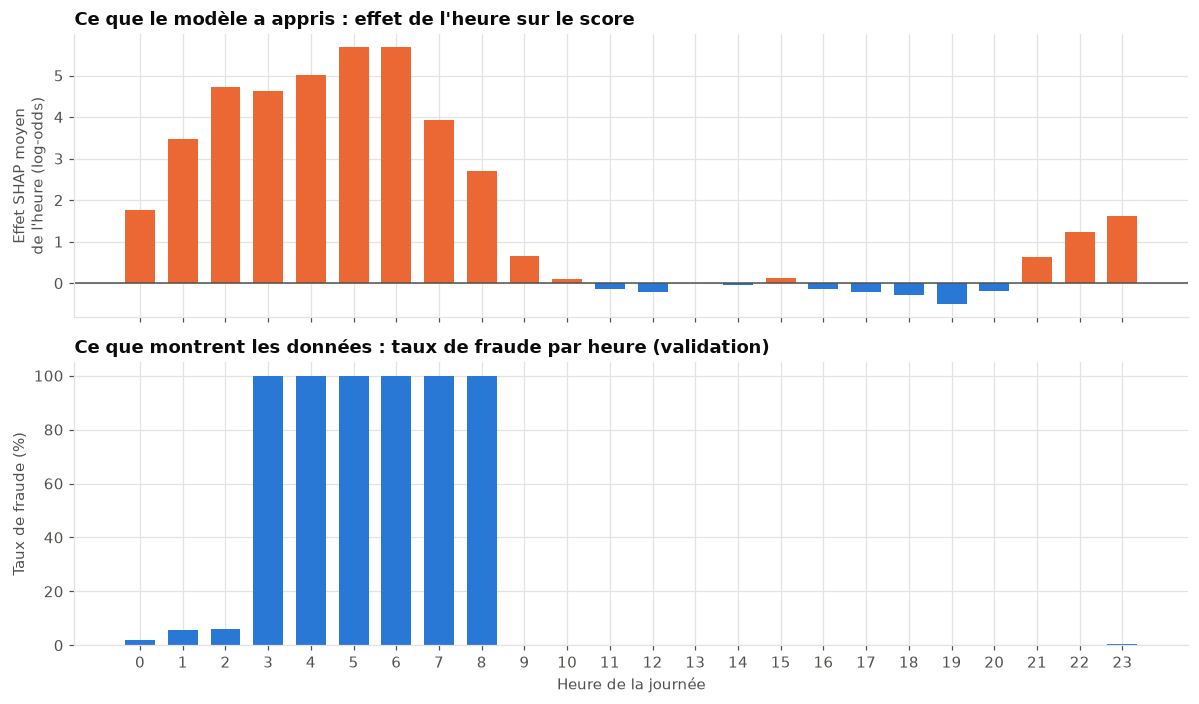

In [8]:
sv_t = shap_vals["transaction"]
hour = (sample["step"] % 24).to_numpy()
hour_effect = sv_t[["heure_sin", "heure_cos", "is_night"]].sum(axis=1).to_numpy()
by_hour = pd.DataFrame({"heure": hour, "effet": hour_effect, "fraude": y_s}).groupby("heure").agg(
    effet_moyen=("effet", "mean"))
by_hour["taux_fraude_val"] = val.groupby(val["step"] % 24)[TARGET].mean()

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
axes[0].bar(by_hour.index, by_hour["effet_moyen"], width=0.7,
            color=[COLOR_FRAUD if v > 0 else COLOR_LEGIT for v in by_hour["effet_moyen"]])
axes[0].axhline(0, color=TEXT_SECONDARY, linewidth=1)
axes[0].set_ylabel("Effet SHAP moyen\nde l'heure (log-odds)")
axes[0].set_title("Ce que le modèle a appris : effet de l'heure sur le score", loc="left")
axes[1].bar(by_hour.index, 100 * by_hour["taux_fraude_val"], width=0.7, color=MODEL_COLORS[0])
axes[1].set_ylabel("Taux de fraude (%)")
axes[1].set_title("Ce que montrent les données : taux de fraude par heure (validation)", loc="left")
axes[1].set_xlabel("Heure de la journée")
axes[1].set_xticks(range(24))
fig.tight_layout()
save_fig(fig, "08_effet_heure")
plt.show()

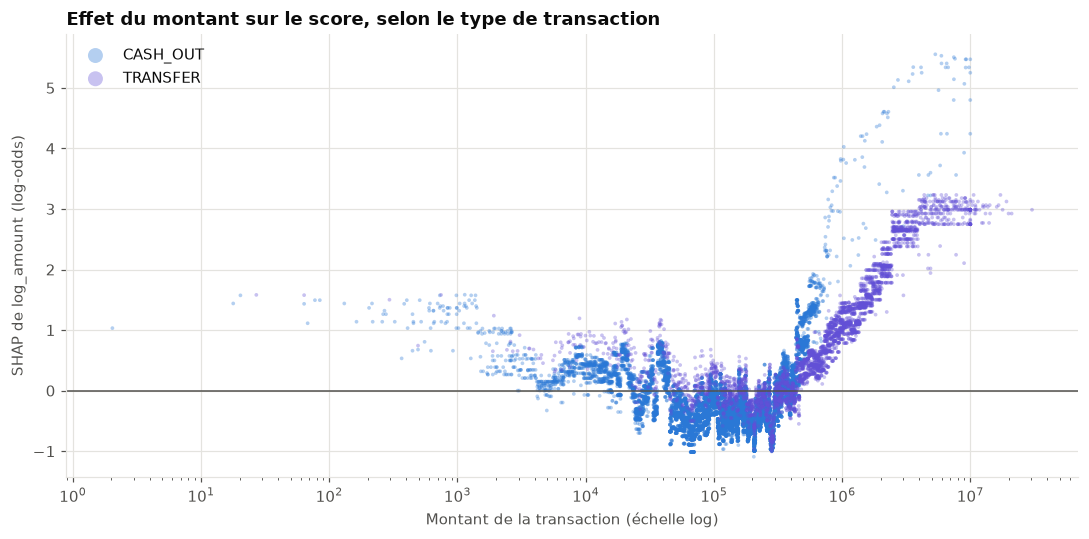

SHAP moyen de is_transfer : TRANSFER = +0.83, CASH_OUT = -0.17


In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
amount = sample["amount"].to_numpy()
is_tr = feats["transaction"]["is_transfer"].to_numpy() == 1
for m, color, label in [(~is_tr, MODEL_COLORS[0], "CASH_OUT"), (is_tr, MODEL_COLORS[2], "TRANSFER")]:
    ax.scatter(amount[m], sv_t["log_amount"].to_numpy()[m], s=6, alpha=0.35, color=color,
               label=label, edgecolor="none")
ax.axhline(0, color=TEXT_SECONDARY, linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Montant de la transaction (échelle log)")
ax.set_ylabel("SHAP de log_amount (log-odds)")
ax.set_title("Effet du montant sur le score, selon le type de transaction", loc="left")
ax.legend(loc="upper left", markerscale=4)
fig.tight_layout()
save_fig(fig, "08_effet_montant")
plt.show()

print("SHAP moyen de is_transfer : TRANSFER = {:+.2f}, CASH_OUT = {:+.2f}".format(
    sv_t["is_transfer"][is_tr].mean(), sv_t["is_transfer"][~is_tr].mean()))

### Un nouvel artefact : les heures sans aucune transaction légitime

Le graphique du bas montre un taux de fraude de **100 %** entre 3 h et 8 h sur la validation. On vérifie les volumes horaires.

In [10]:
hourly = pd.crosstab(val["step"] % 24, val[TARGET]).rename(columns={0: "légitimes", 1: "fraudes"})
hourly.index.name = "heure"
print(hourly.T.to_string())
empty = hourly.index[hourly["légitimes"] == 0].tolist()
print()
print(f"Heures sans aucune transaction légitime : {empty}")
print(f"Part des fraudes de la validation tombant à ces heures : "
      f"{hourly.loc[empty, 'fraudes'].sum() / hourly['fraudes'].sum():.1%}")

from sklearn.metrics import average_precision_score, roc_auc_score
y_val = val[TARGET].to_numpy()
s_val = models["transaction"].predict_proba(val)[:, 1]
keep = ~(val["step"] % 24).isin(empty).to_numpy()
artefact_heures = pd.DataFrame({
    "toutes les heures": [average_precision_score(y_val, s_val), roc_auc_score(y_val, s_val), y_val.mean()],
    "hors heures vides": [average_precision_score(y_val[keep], s_val[keep]),
                          roc_auc_score(y_val[keep], s_val[keep]), y_val[keep].mean()],
}, index=["PR-AUC", "ROC-AUC", "prévalence"])
_ = save_results(artefact_heures, "08_artefact_heures")
artefact_heures

heure        0    1    2   3   4   5   6   7   8      9      10     11     12     13     14     15     16     17     18     19     20     21    22    23
isFraud                                                                                                                                                 
légitimes  1535  331  158   0   0   0   0   0   0  13720  23447  26794  26041  26015  24585  23791  24322  28484  35746  38928  29402  10420  7283  4848
fraudes      28   20   10  22  22  30  20  20  20     20     22     10     18     28     28     28     34     14     22     14     12     26    14    16

Heures sans aucune transaction légitime : [3, 4, 5, 6, 7, 8]
Part des fraudes de la validation tombant à ces heures : 26.9%


,toutes les heures,hors heures vides
PR-AUC,0.375,0.181
ROC-AUC,0.878,0.834
prévalence,0.001,0.001


**Lecture**
- **Type (H1)** : un TRANSFER ajoute en moyenne **+0,83** au score, un CASH_OUT **−0,17**, ce qui est cohérent avec le taux de fraude plus élevé des transferts.
- **Montant (H2)** : l'effet est **non linéaire**, ce qui explique l'échec de la régression logistique.
  - Entre 50 000 et 400 000, montants typiques des légitimes, l'effet est négatif.
  - Au-delà de 500 000, il croît fortement : jusqu'à **+3** pour les TRANSFER, avec un plateau vers 10 M qui correspond au **plafond** des fraudes simulées, et jusqu'à +5,5 pour quelques gros CASH_OUT.
  - Les tout petits montants (< 1 000) sont aussi légèrement suspects.
- **Heure (H5)** : le modèle a appris un effet très fort, de **+3,5 à +5,7 log-odds** entre 1 h et 7 h, contre ≈ 0 en journée.

**Mais cet effet de l'heure est un artefact du simulateur.**
- Les **fraudes sont générées à un rythme constant** : environ 20 par heure, à **toute** heure du jour.
- Les **transactions légitimes** suivent un cycle journalier et tombent à **zéro entre 3 h et 8 h** (sur la validation comme sur le test).
- Résultat : **27 % des fraudes** surviennent à des heures où il n'existe **aucune** transaction légitime. Les repérer ne demande aucune intelligence : toute transaction à 5 h du matin est une fraude.
- C'est l'origine du **plateau de précision ≈ 100 % jusqu'à ~30 % de rappel** observé aux notebooks 06 et 07.
- En retirant ces heures, la PR-AUC du modèle `transaction` passe de **0,375 à 0,181** sur la validation, et la ROC-AUC de 0,878 à 0,834. **La moitié de sa PR-AUC vient de cet artefact.**
- Il reste un **vrai signal** : 0,181, c'est encore environ 170 fois le hasard. Il repose sur le **montant** et le **type**.

➡️ H5 est **confirmée statistiquement** (notebook 02), mais son **interprétation** doit être corrigée. Ce n'est pas que les fraudeurs préfèrent la nuit : le simulateur ne fait pas varier l'activité des fraudeurs selon l'heure, alors que les clients légitimes dorment. Sur des données réelles, cet effet serait bien plus faible.

## 5. Explications individuelles

On explique quatre décisions du modèle `transaction` au **seuil retenu au notebook 07**, et une décision du modèle `complet` :
1. une **fraude détectée** (score médian parmi les fraudes détectées) ;
2. la **fraude manquée la plus coûteuse** (plus gros montant sous le seuil) ;
3. la **fausse alerte la plus forte** (transaction légitime au score le plus élevé) ;
4. une **transaction légitime typique** (score médian des légitimes) ;
5. pour le modèle `complet` : une **fraude plafonnée à 10 M** que la règle « compte vidé » ratait (notebook 05).

In [11]:
score_t = models["transaction"].predict_proba(sample)[:, 1]
alert = score_t >= THRESHOLD["transaction"]

def median_pick(mask):
    idx = np.flatnonzero(mask)
    return idx[np.argsort(score_t[idx])[len(idx) // 2]]

cases = {
    "Fraude détectée (cas médian)": median_pick((y_s == 1) & alert),
    "Fraude manquée la plus coûteuse": np.flatnonzero((y_s == 1) & ~alert)[
        np.argmax(amount[(y_s == 1) & ~alert])],
    "Fausse alerte la plus forte": np.flatnonzero(y_s == 0)[np.argmax(score_t[y_s == 0])],
    "Légitime typique (cas médian)": median_pick(y_s == 0),
}
cols = ["step", "type", "amount", "isFraud"]
pd.DataFrame({k: sample.iloc[i][cols] for k, i in cases.items()}).T.assign(
    heure=lambda d: d["step"].astype(int) % 24, score=[score_t[i] for i in cases.values()])

,step,type,amount,isFraud,heure,score
Fraude détectée (cas médian),325,CASH_OUT,"1,445,166.740",1,13,0.988
Fraude manquée la plus coûteuse,352,TRANSFER,"7,454,553.060",1,16,0.820
Fausse alerte la plus forte,338,TRANSFER,"2,689,227.940",0,2,0.988
Légitime typique (cas médian),327,CASH_OUT,"229,001.210",0,15,0.160


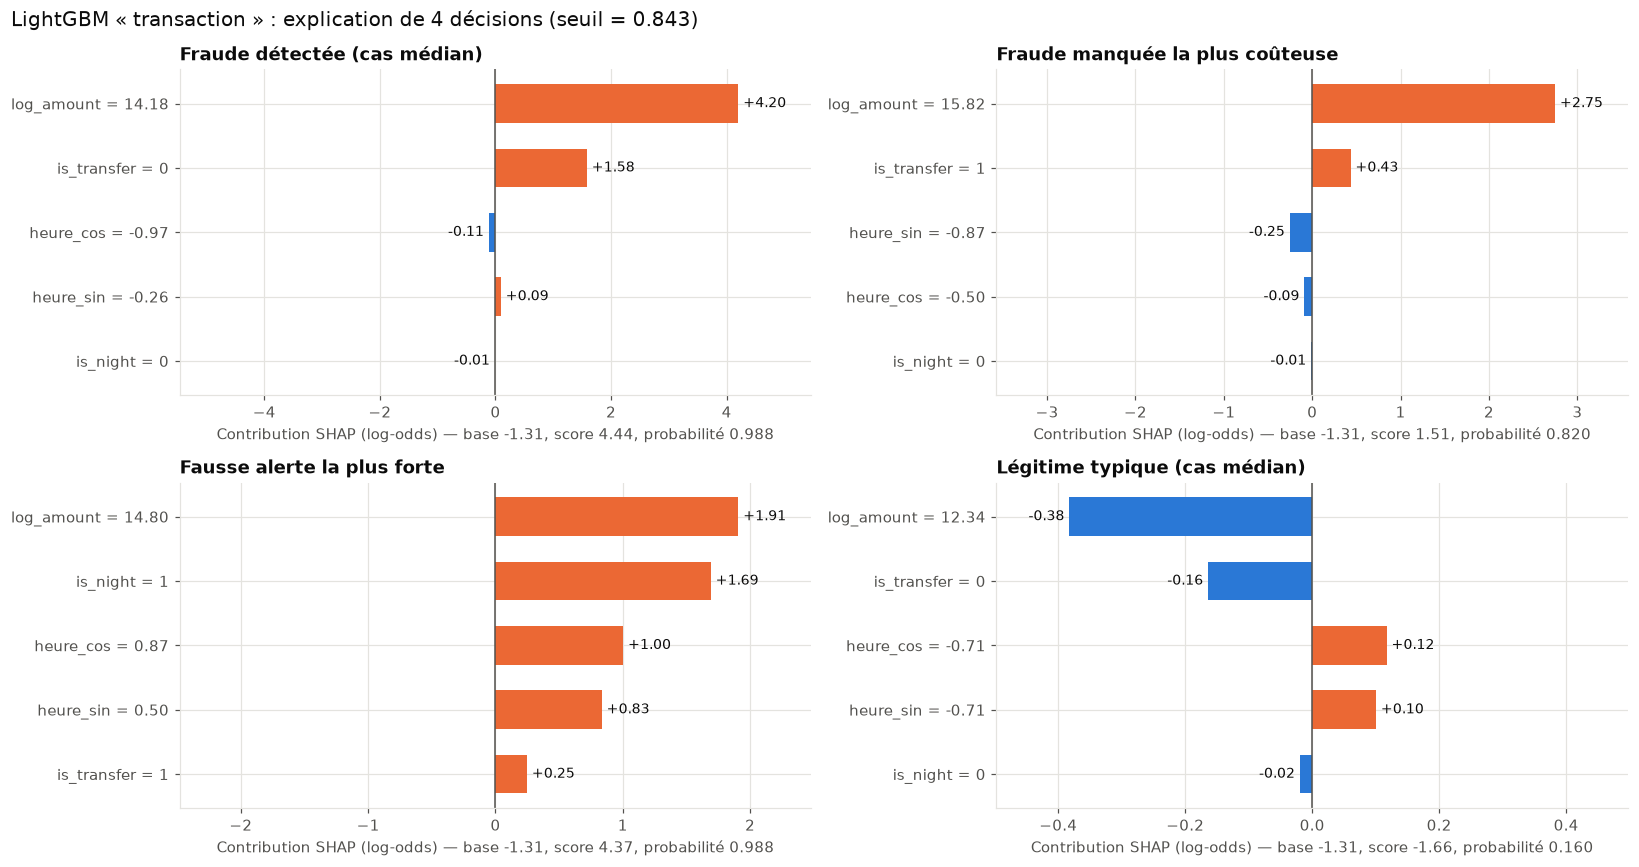

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, (title, i) in zip(axes.ravel(), cases.items()):
    plot_contributions(ax, sv_t.iloc[i], feats["transaction"].iloc[i], base["transaction"],
                       max_features=5, title=title)
fig.suptitle("LightGBM « transaction » : explication de 4 décisions "
             f"(seuil = {THRESHOLD['transaction']:.3f})", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save_fig(fig, "08_explications_locales_transaction")
plt.show()

Fraudes plafonnées à 10 M sans compte vidé dans l'échantillon : 4
step                        312
type                   TRANSFER
amount           10,000,000.000
oldbalanceOrig   16,580,427.810
newbalanceOrig    6,580,427.810
oldbalanceDest            0.000
newbalanceDest            0.000


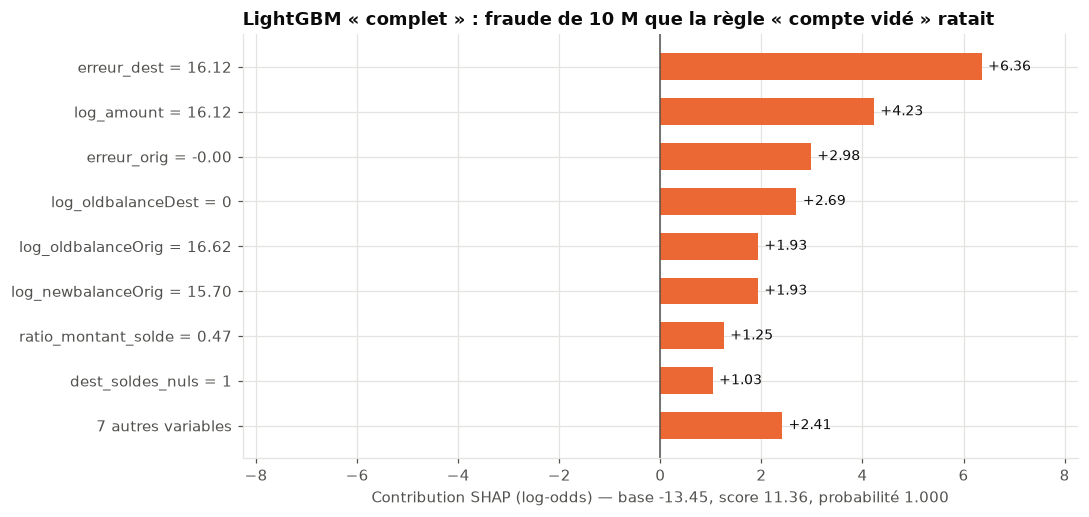

In [13]:
capped = np.flatnonzero((y_s == 1) & (amount == 1e7) & (feats["complet"]["compte_vide"].to_numpy() == 0))
print(f"Fraudes plafonnées à 10 M sans compte vidé dans l'échantillon : {len(capped)}")
i = capped[0]
print(sample.iloc[i][["step", "type", "amount", "oldbalanceOrig", "newbalanceOrig",
                      "oldbalanceDest", "newbalanceDest"]].to_string())
fig, ax = plt.subplots(figsize=(10, 4.8))
plot_contributions(ax, shap_vals["complet"].iloc[i], feats["complet"].iloc[i], base["complet"],
                   max_features=8, title="LightGBM « complet » : fraude de 10 M que la règle « compte vidé » ratait")
fig.tight_layout()
save_fig(fig, "08_explication_fraude_plafonnee")
plt.show()

**Lecture des explications individuelles**
- **Fraude détectée** (CASH_OUT de 1,45 M à 13 h, probabilité 0,988) : le **montant** apporte +4,2. Le fait d'être un CASH_OUT apporte ici +1,6, alors qu'en moyenne un CASH_OUT fait baisser le score : c'est une **interaction** montant × type. Un CASH_OUT de ce montant est rare chez les légitimes.
- **Fraude manquée la plus coûteuse** (TRANSFER de 7,45 M à 16 h) : probabilité de **0,820**, juste sous le seuil (0,843). Le montant (+2,8) et le type (+0,4) poussent vers la fraude, mais l'heure de **journée** la tire légèrement vers « légitime » (−0,3). C'est un cas limite : un gros transfert en pleine journée ressemble à une opération légitime.
- **Fausse alerte la plus forte** (TRANSFER légitime de 2,69 M à **2 h**) : les variables horaires cumulent **+3,5**, le montant +1,9. Le modèle ne peut pas distinguer un gros transfert nocturne légitime d'une fraude : c'est la limite d'un modèle à 5 variables.
- **Légitime typique** (CASH_OUT de 229 000 à 15 h) : montant et type courants, score bas (0,160), loin du seuil.
- **Fraude plafonnée à 10 M** (modèle `complet`) : `compte_vide` vaut 0 (le compte contenait 16,6 M), mais le modèle la détecte quand même avec une probabilité de 1,000. Il cumule d'autres signaux :
  - le destinataire **n'a pas été crédité** (`erreur_dest` : +6,4) ;
  - le **montant** est de 10 M (+4,2) ;
  - le solde émetteur est **parfaitement cohérent** (`erreur_orig` : +3,0) ;
  - le **solde destinataire est nul** (+2,7).

  C'est ce qui lui permet de battre la règle « compte vidé » : il combine **plusieurs artefacts** au lieu d'un seul.

> Remarque : les probabilités affichées ne sont **pas calibrées** (la pondération des classes les gonfle). Seul l'**ordre** des scores et leur position par rapport au seuil ont un sens.

## 6. Conclusions

### Ce que SHAP révèle

| Modèle | Ce sur quoi il s'appuie | Nature du signal |
|---|---|---|
| LightGBM `complet` | compte vidé (+18 log-odds), soldes émetteurs « trop cohérents », destinataire non crédité | **artefacts du simulateur** (H3, H4) |
| LightGBM `transaction` | heure (fraudes aux heures sans activité légitime), montant élevé, type TRANSFER | **mi-artefact** (heures vides), **mi-signal réel** (montant, type) |

### Retour sur les hypothèses

| Hypothèse | Verdict EDA (notebook 02) | Ce que montre SHAP |
|---|---|---|
| **H1** : la fraude dépend du type | confirmée (V = 0,06) | TRANSFER : +0,83 en moyenne, CASH_OUT : −0,17 |
| **H2** : les fraudes ont des montants plus élevés | confirmée (r = 0,37) | effet non linéaire, fortement positif au-delà de 500 000, plateau au plafond de 10 M |
| **H3** : les fraudes vident le compte | confirmée (V = 0,99) | première variable sur les fraudes (+17,9 log-odds), **artefact** |
| **H4** : les erreurs de solde sont discriminantes | confirmée | soldes exacts → fraude, soldes incohérents → légitime, **artefact** |
| **H5** : la fraude est plus fréquente la nuit | confirmée (V = 0,31) | effet le plus fort du modèle `transaction`, mais **artefact** : 27 % des fraudes tombent à des heures sans aucune transaction légitime |

### Enseignements
1. **SHAP confirme et précise les conclusions de l'EDA** : les modèles ont appris exactement les signaux identifiés par les tests statistiques, et SHAP en donne le **sens**, la **forme** (non linéaire pour le montant) et les **interactions** (montant × type).
2. **SHAP a révélé un artefact que l'EDA n'avait pas identifié comme tel** : l'absence totale de transactions légitimes entre 3 h et 8 h. La moitié de la PR-AUC du modèle `transaction` en dépend. Sans le volet explicabilité, on aurait surestimé la qualité de ce modèle.
3. **Il faut lire deux importances** : sur la population (variables les plus souvent utilisées) et sur les fraudes (comment une fraude est reconnue). Une variable rare mais décisive (`compte_vide`) est invisible dans la première.
4. **Une importance faible ne signifie pas une variable inutile** : `dest_soldes_nuls` est redondante avec les soldes destinataires.

### Conséquence sur les conclusions précédentes
Le notebook 07 présentait LightGBM `transaction` comme le modèle « le plus crédible » pour une situation réelle. Ce jugement doit être **nuancé** : il est moins dépendant des artefacts que le modèle `complet`, mais **pas exempt**. Sa performance réaliste est plutôt de l'ordre d'une **PR-AUC de 0,18 à 0,23** (hors heures vides, validation et test), portée par le montant et le type.

### Suite (Phase 10)
**Pipeline d'entraînement** : un script `src/train.py` qui reproduit de bout en bout l'entraînement des modèles retenus (données → découpage → modèles → seuils → sauvegarde), en une seule commande.